# TicketIQ demo

A support ticket goes through a from-scratch **Naive Bayes** classifier, **VADER** aspect sentiment, a
**contextual bandit** that picks the answering strategy, **FAISS** retrieval of company policy, and a
**ReAct agent** that reasons, calls tools and replies.

Runs in seconds on a laptop. With [Ollama](https://ollama.com) running (`qwen2.5:1.5b`, `llama3.2:1b`) the
agent uses the local LLMs; without it, the offline template writer answers and the trace says so.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np

import reproduce as R
from ticketiq.classifier import CATEGORIES, TicketClassifierService
from ticketiq.config import SETTINGS
from ticketiq.triage import TicketIQ

## 1. Classifier: Naive Bayes written from scratch
Trained on a stratified 75 / 25 split of 160 synthetic tickets; 45% of tickets mix in a sentence from a second
category so the task is not trivially easy. Scored on the 40 held-out tickets with scikit-learn.

held-out accuracy 0.950 | macro F1 0.949 | 40 test tickets


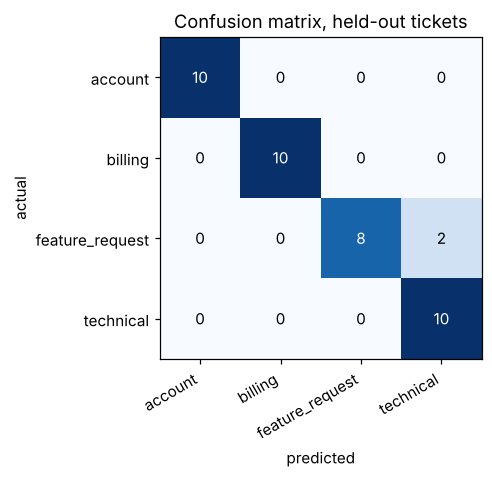

In [2]:
clf = TicketClassifierService(SETTINGS.tickets_file, SETTINGS.test_split, SETTINGS.random_seed).train()
ev = clf.evaluation
print(f"held-out accuracy {ev['accuracy']:.3f} | macro F1 {ev['macro_f1']:.3f} | {ev['test_size']} test tickets")

cm = np.array([[clf.confusion[a][p] for p in CATEGORIES] for a in CATEGORIES])
plt.figure(figsize=(4.6, 3.8))
plt.imshow(cm, cmap="Blues")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 5 else "black")
plt.xticks(range(4), CATEGORIES, rotation=30, ha="right")
plt.yticks(range(4), CATEGORIES)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix, held-out tickets")

Both mistakes are feature requests read as technical problems: tickets that mention a missing feature
*and* something not working.

## 2. Contextual bandit: learning which strategy works where
4 configurations (concise or empathetic step-by-step prompt × top-2 or top-5 retrieval) across 36 states
(category × urgency × tier). In a simulated world each configuration has a hidden helpfulness and latency;
the bandit only sees rewards, and an oracle that knows the hidden numbers grades its choices.

In [3]:
res = R.bandit_simulation(20000)


BANDIT  20,000 simulated tickets, 36 states, 4 configurations, epsilon 0.15
picked the oracle's configuration: 54.4% of the first 1,000 tickets, 67.7% of the first 4,000, 88.8% of the last 4,000
ceiling with 15% exploration: 88.8%   average reward 6.10 in the first block -> 6.84 in the last


How often it picked the oracle's configuration, over a sliding window of 500 tickets (same simulation, same
seed):

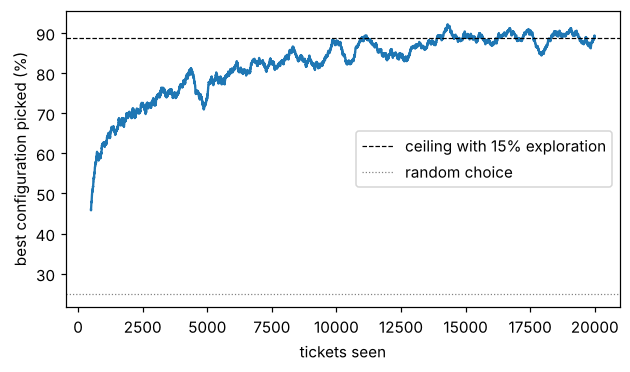

In [4]:
rng = random.Random(R.SEED)
bandit = R.EpsilonGreedyContextualBandit(R.all_config_names(), epsilon=R.EPSILON, seed=R.SEED)
hits = []
for _ in range(20000):
    c, u, tier = rng.choice(R.SIM_CATEGORIES), rng.choice(R.URGENCY_BUCKETS), rng.choice(R.TIERS)
    state = R.build_state_key(c, u, tier)
    action, _ = bandit.select_action(state)
    latency = R.simulate_latency(action, rng)
    bandit.update(state, action, R.compute_reward(R.simulate_feedback(action, u, tier, rng), latency))
    hits.append(action == R.oracle(u, tier))
rolling = np.convolve(hits, np.ones(500) / 500, mode="valid")
plt.figure(figsize=(6.5, 3.5))
plt.plot(np.arange(500, 20001), rolling * 100)
plt.axhline(res["ceiling_with_exploration"] * 100, color="k", ls="--", lw=0.8, label="ceiling with 15% exploration")
plt.axhline(25, color="grey", ls=":", lw=0.8, label="random choice")
plt.xlabel("tickets seen")
plt.ylabel("best configuration picked (%)")
plt.legend()

## 3. One ticket end to end
Classification, aspect sentiment, urgency, the bandit's choice, the retrieved policy, the agent's reasoning
trace and the reply.

In [5]:
app = TicketIQ()


def show(ticket):
    print(f"category {ticket['category']} ({ticket['category_confidence']:.0%}) | urgency {ticket['urgency_bucket']} "
          f"| state {ticket['state_key']} | strategy {ticket['config']} | LLM backend {ticket['llm_backend']}")
    for a in ticket["aspect_sentiments"]:
        print(f"  sentiment  {a['aspect']:10s} {a['score']:+.2f}")
    for k in ticket["retrieved_knowledge"]:
        print(f"  retrieved  {k['document_title']} / {k['heading']}  (score {k['score']})")
    for step in ticket["reasoning_trace"]:
        print(f"  step {step['step']}: {step['action']}  - {step['thought'][:90]}")
    print(f"decision: {ticket['action']}\n\n{ticket['response_text']}")


billing = app.handle("Charged twice this month",
                     "I was billed twice for my Pro plan on invoice INV-2041. Really frustrating, please refund the "
                     "duplicate charge.", "enterprise")
show(billing)

category billing (100%) | urgency medium | state billing|medium|enterprise | strategy concise_policy|k2 | LLM backend template
  sentiment  billing    -0.28
  retrieved  Billing and Refund Policy / Duplicate charges  (score 0.4015)
  retrieved  Billing and Refund Policy / Cancellations  (score 0.1517)
  step 1: check_refund_eligibility  - The customer is asking for money back, so eligibility must be confirmed before anything is
  step 2: answer  - The retrieved knowledge base sections cover this question, so it can be answered directly.
decision: answer

Category: billing. Applicable policy - Duplicate charges: If the same amount was charged twice within one billing cycle, the duplicate is always refunded in full, regardless of the 30 day window. Cancellations: Cancelling stops future renewals immediately. Checked: check_refund_eligibility -> order 2041 is eligible for a refund of 761.5 (within the 30 day refund window). Applying the rule above resolves this request.


A feature request. These are never escalated to a human: if the model ever chooses to escalate one, a rule in
code overrides it and the trace records the override.

In [6]:
show(app.handle("Please add dark mode", "Would love a dark mode option for the dashboard, my eyes get tired at night.",
                "free"))

category feature_request (100%) | urgency low | state feature_request|low|free | strategy concise_policy|k2 | LLM backend template
  sentiment  feature_availability +0.32
  retrieved  Feature Request Handling / Never escalate a feature request as an incident  (score 0.3485)
  retrieved  Feature Request Handling / What support should do  (score 0.2374)
  step 1: answer  - The retrieved knowledge base sections cover this question, so it can be answered directly.
decision: answer

Category: feature_request. Applicable policy - Never escalate a feature request as an incident: A missing feature is not an outage. What support should do: Never promise a delivery date for a requested feature. Applying the rule above resolves this request.


## 4. Feedback closes the loop
The customer's rating and the measured latency become a reward that updates the bandit for that state.

In [7]:
print(f"reward for a helpful answer: {app.feedback(billing, 1):.2f}")
print("bandit's current best strategy for", billing["state_key"], "->", app.bandit.best_action(billing["state_key"]))

reward for a helpful answer: 10.00
bandit's current best strategy for billing|medium|enterprise -> concise_policy|k2
